In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix, classification_report

**House Price Prediction (Linear Regression)**

In [4]:
# 1. Load Dataset
df_housing = pd.read_csv('Housing.csv')

2. Preprocess Categorical Variables
Convert binary 'yes'/'no' features to 1/0

In [6]:
# Reload to ensure a clean state and map binary variables safely
df_housing = pd.read_csv('Housing.csv')

binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for col in binary_cols:
    df_housing[col] = df_housing[col].map({'yes': 1, 'no': 0})

# One-Hot Encoding for 'furnishingstatus'
if 'furnishingstatus' in df_housing.columns:
    df_housing = pd.get_dummies(df_housing, columns=['furnishingstatus'], drop_first=True, dtype=int)

print("Preprocessing completed successfully. No missing values remaining:", df_housing.isnull().sum().sum())

In [11]:
# Inspect columns of df_housing to verify names and find the categorical columns
print("Columns in dataset:", list(df_housing.columns))
display(df_housing.head())

Columns in dataset: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,NaN,NaN,NaN,NaN,NaN,2,NaN,0,0
1,12250000,8960,4,4,4,NaN,NaN,NaN,NaN,NaN,3,NaN,0,0
2,12250000,9960,3,2,2,NaN,NaN,NaN,NaN,NaN,2,NaN,1,0
3,12215000,7500,4,2,2,NaN,NaN,NaN,NaN,NaN,3,NaN,0,0
4,11410000,7420,4,1,2,NaN,NaN,NaN,NaN,NaN,2,NaN,0,0


In [12]:
# 3. Define Features (X) and Target (y)
X_house = df_housing.drop(columns=['price'])
y_house = df_housing['price']

In [14]:
# 4. Train/Test Split (80% Train, 20% Test)
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(X_house, y_house, test_size=0.2, random_state=42)

In [19]:
# Clean reload and preprocessing pipeline
df_housing = pd.read_csv('Housing.csv')

# Map binary features to 1/0
binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for col in binary_cols:
    df_housing[col] = df_housing[col].map({'yes': 1, 'no': 0})

# One-hot encode furnishingstatus
df_housing = pd.get_dummies(df_housing, columns=['furnishingstatus'], drop_first=True, dtype=int)

# Set features (X) and target (y)
X_house = df_housing.drop(columns=['price'])
y_house = df_housing['price']

# Split into training and test sets
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(X_house, y_house, test_size=0.2, random_state=42)

# Initialize and fit the Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train_h, y_train_h)

print("Model trained successfully! R2 score on training set:", lr_model.score(X_train_h, y_train_h))

Model trained successfully! R2 score on training set: 0.6859438988560158


In [20]:
# 6. Predict and Evaluate Model
y_pred_h = lr_model.predict(X_test_h)
mse_h = mean_squared_error(y_test_h, y_pred_h)
r2_h = r2_score(y_test_h, y_pred_h)

In [21]:
print("=== MINI PROJECT 2: LINEAR REGRESSION RESULTS ===")
print(f"Mean Squared Error (MSE): {mse_h:,.2f}")
print(f"R² Score: {r2_h:.4f}")

=== MINI PROJECT 2: LINEAR REGRESSION RESULTS ===
Mean Squared Error (MSE): 1,754,318,687,330.66
R² Score: 0.6529


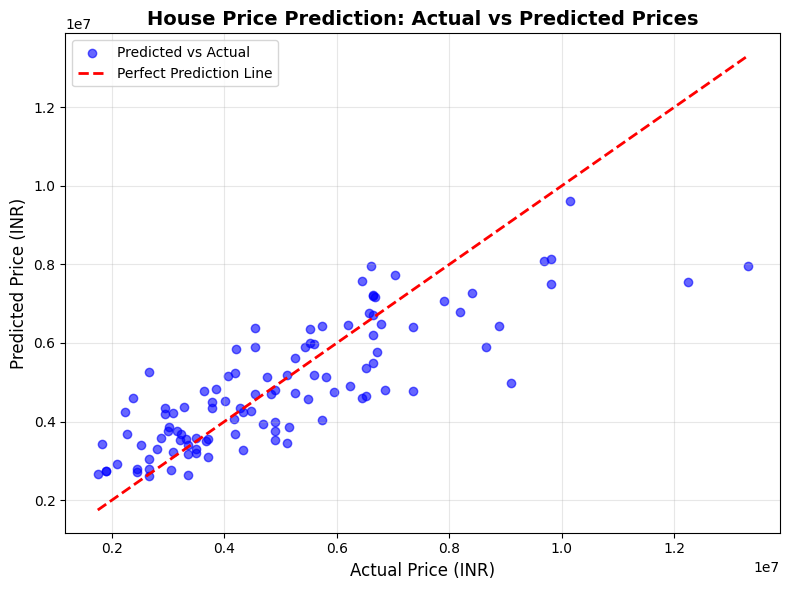

In [23]:
# 7. Plot Predicted vs Actual Values
plt.figure(figsize=(8, 6))
plt.scatter(y_test_h, y_pred_h, color='blue', alpha=0.6, label='Predicted vs Actual')
plt.plot([y_test_h.min(), y_test_h.max()], [y_test_h.min(), y_test_h.max()], 'r--', lw=2, label='Perfect Prediction Line')
plt.title('House Price Prediction: Actual vs Predicted Prices', fontsize=14, fontweight='bold')
plt.xlabel('Actual Price (INR)', fontsize=12)
plt.ylabel('Predicted Price (INR)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()